# Árvore de decisão rasa: o modelo que o gestor consegue ler (Fase 3)

**Objetivo:** quarto modelo do grupo. A Random Forest e o boosting (notebooks 04 e 05) empatam
em desempenho com a regressão logística; a árvore rasa entra por outro motivo: é a única que
vira **regras que um gestor público consegue ler, questionar e discutir**
("municípios com taxa do ano anterior abaixo de X e fora do Sudeste têm risco de Y%").
Ela responde ao trade-off **desempenho × interpretabilidade** que o README pede.

O fluxo é o mesmo dos notebooks 04 e 05, para a comparação ser justa. O código reutilizável
fica em `src/`.

| Etapa | Aula de referência |
|---|---|
| Árvores de decisão e class_weight |  |
| Curva de validação (complexidade × overfitting) |  |
| `GridSearchCV` com validação cruzada |  |
| Limiar, teste uma única vez, métricas | |
| Importância e SHAP |  |

Duas escolhas técnicas deste notebook:

- **Sem log e sem padronização.** Árvores são invariantes a transformações monotônicas: as
  divisões são as mesmas. Sem a escala, os limiares das regras aparecem em **unidades
  originais** (ex.: `mun_taxa_ano_anterior <= 0.62`), não em z-scores. O pré-processamento só
  imputa e aplica one-hot.
- **`min_samples_leaf` como fração.** A busca roda numa amostra (~126 mil linhas) e o treino
  final na base inteira (~1,3 milhão). Uma fração mantém o mesmo tamanho **relativo** de folha
  nos dois.

Os `TODO` dependem dos números da sua execução.

## 1. Setup

In [1]:
import sys
import time
import json
import warnings
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))   # raiz do repositório no path (para importar src/)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GridSearchCV, GroupKFold, validation_curve

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 220)

from src.preprocessing.pipeline import preparar_dados
from src.modeling.modelos import limitar_por_municipio
from src.modeling.treinar import treinar_sem_busca
from src.modeling.arvore import GRADE_BUSCA, criar_pipeline_arvore
from src.evaluation.avaliacao import (PASTA_RELATORIOS, calcular_shap, escolher_limiar,
                                      importancia_permutacao, probas_fora_da_amostra, salvar_resultados)
from src.evaluation.comparar_teste import comparar_teste
from src.evaluation.regras import regras_da_arvore
from src.visualization.graficos import (plot_avaliacao_teste, plot_importancias,
                                        plot_precisao_recall_cv, plot_shap)
from src.visualization.graficos_arvore import plot_arvore, plot_curva_validacao

TETO_ALUNOS = 30        # alunos por município na busca de hiperparâmetros e na escolha do limiar
TETO_PERMUTACAO = 20    # alunos por município do teste na permutation importance
TETO_SHAP = 3           # alunos por município do teste no SHAP
META_RECALL = 0.70      # ponto de partida do limiar (decisão do grupo)

NOME = "arvore_rasa"
ROTULO = "Árvore de decisão (rasa)"
PASTA_RELATORIOS.mkdir(parents=True, exist_ok=True)

## 2. Dados e amostra com teto por município

Mesma divisão por município e mesmo teto dos notebooks 04 e 05 (a justificativa está no 04):
nenhum município aparece em treino e teste, e a amostra com teto serve só para a busca e para a
escolha do limiar.

In [2]:
dados = preparar_dados()
print(f"Treino: {len(dados.y_treino):,} alunos, {dados.g_treino.nunique():,} municípios, risco {dados.y_treino.mean():.1%}")
print(f"Teste:  {len(dados.y_teste):,} alunos, {dados.g_teste.nunique():,} municípios, risco {dados.y_teste.mean():.1%}")

X_am, y_am, g_am = limitar_por_municipio(dados.X_treino, dados.y_treino, dados.g_treino, TETO_ALUNOS)
print(f"Amostra: {len(y_am):,} alunos, {g_am.nunique():,} municípios, risco {y_am.mean():.1%}")

Treino: 1,320,423 alunos, 4,360 municípios, risco 40.9%
Teste:  290,331 alunos, 1,090 municípios, risco 39.3%
Amostra: 125,981 alunos, 4,360 municípios, risco 37.3%


## 3. Quão profunda pode ser uma árvore "rasa"? (curva de validação)

Otimização, Aula 5 (`slide16`): o AUC de treino e o de validação em função da profundidade.
Enquanto os dois sobem juntos, a árvore está aprendendo padrão; quando o de treino continua
subindo e o de validação estaciona, está decorando. A validação é **por município**
(`GroupKFold`), para o score não ser inflado.

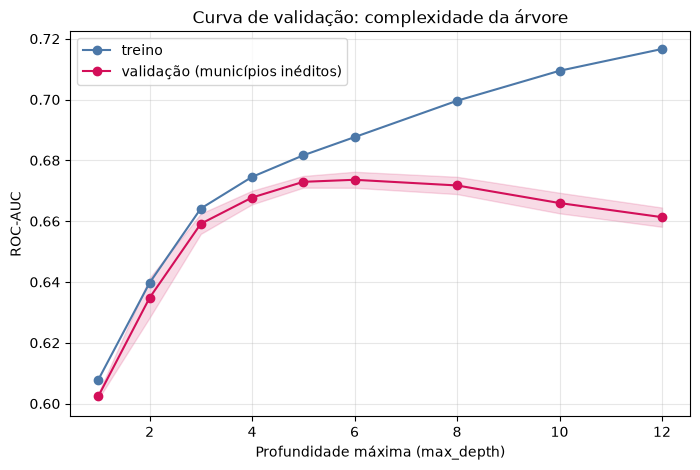

,AUC treino,AUC validação,desvio validação,gap
max_depth,,,,
1,0.6079,0.6024,0.0009,0.0054
2,0.6397,0.6348,0.0065,0.0049
3,0.6642,0.6592,0.0033,0.0050
4,0.6746,0.6678,0.0022,0.0068
5,0.6817,0.6729,0.0019,0.0087
6,0.6876,0.6736,0.0026,0.0140
8,0.6996,0.6717,0.0028,0.0279
10,0.7095,0.6660,0.0034,0.0435
12,0.7166,0.6613,0.0032,0.0553


In [3]:
profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 12]
treino_sc, valid_sc = validation_curve(
    criar_pipeline_arvore(dados.decisoes, min_samples_leaf=0.002), X_am, y_am,
    param_name="modelo__max_depth", param_range=profundidades,
    groups=g_am, cv=GroupKFold(n_splits=3), scoring="roc_auc",
)
auc_tr, auc_va, sd_va = treino_sc.mean(axis=1), valid_sc.mean(axis=1), valid_sc.std(axis=1)

plot_curva_validacao(np.array(profundidades), auc_tr, auc_va, sd_va,
                     "Profundidade máxima (max_depth)", "arvore_curva_validacao.png")
tabela_curva = pd.DataFrame({"AUC treino": auc_tr, "AUC validação": auc_va,
                             "desvio validação": sd_va, "gap": auc_tr - auc_va}, index=profundidades)
tabela_curva.index.name = "max_depth"
display(tabela_curva.round(4))

**Leitura** (`TODO`: confirmar com o seu gráfico): procure a profundidade a partir da qual o AUC
de validação para de melhorar e o gap (treino - validação) começa a crescer. O esperado, como
nos outros modelos, é um **platô cedo**: poucos níveis já capturam quase todo o sinal, e níveis
extras só decoram municípios.

## 4. Busca de hiperparâmetros (`GridSearchCV`)

Árvores são baratas, então a busca é **exaustiva** (Otimização, Aula 2): 6 profundidades x 4
tamanhos mínimos de folha, com `GroupKFold`. O critério de seleção é o ROC-AUC.

**Regra do desvio padrão:** nos outros modelos, as combinações ficaram estatisticamente
empatadas. Aqui, entre as combinações cujo AUC está **dentro de 1 desvio padrão da melhor**,
escolhe-se a **mais simples** (menor profundidade e, no empate, folhas maiores). Para um modelo
cujo propósito é ser lido, é a escolha coerente.

In [4]:
busca = GridSearchCV(
    criar_pipeline_arvore(dados.decisoes), param_grid=GRADE_BUSCA,
    cv=GroupKFold(n_splits=3),
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall"},
    refit="roc_auc", n_jobs=-1, verbose=1,
)
t0 = time.time()
busca.fit(X_am, y_am, groups=g_am)
print(f"Busca concluída em {(time.time() - t0) / 60:.1f} min")

res = pd.DataFrame(busca.cv_results_)
res["max_depth"] = res["param_modelo__max_depth"].astype(int)
res["min_samples_leaf"] = res["param_modelo__min_samples_leaf"].astype(float)
res = res.rename(columns={"mean_test_roc_auc": "roc_auc", "std_test_roc_auc": "desvio_auc",
                          "mean_test_pr_auc": "pr_auc", "mean_test_recall": "recall"})
tabela_busca = (res[["max_depth", "min_samples_leaf", "roc_auc", "desvio_auc", "pr_auc", "recall"]]
                .sort_values("roc_auc", ascending=False).reset_index(drop=True))
display(tabela_busca.head(10).round(4))

melhor_linha = tabela_busca.iloc[0]
limite_1dp = melhor_linha["roc_auc"] - melhor_linha["desvio_auc"]
empatadas = tabela_busca[tabela_busca["roc_auc"] >= limite_1dp]
escolhida = empatadas.sort_values(["max_depth", "min_samples_leaf"], ascending=[True, False]).iloc[0]

params_arvore = {"max_depth": int(escolhida["max_depth"]), "min_samples_leaf": float(escolhida["min_samples_leaf"])}
print(f"Melhor AUC: {melhor_linha['roc_auc']:.4f} (max_depth={int(melhor_linha['max_depth'])}, "
      f"folha={melhor_linha['min_samples_leaf']:.3f})")
print(f"Empatadas dentro de 1 desvio padrão: {len(empatadas)} de {len(tabela_busca)} combinações")
print(f"Árvore escolhida (a mais simples entre as empatadas): {params_arvore} | AUC {escolhida['roc_auc']:.4f}")

tabela_busca.to_csv(PASTA_RELATORIOS / "arvore_rasa_busca.csv", index=False, encoding="utf-8-sig")

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Busca concluída em 0.6 min


,max_depth,min_samples_leaf,roc_auc,desvio_auc,pr_auc,recall
0,8,0.010,0.6749,0.0018,0.5314,0.6296
1,6,0.010,0.6747,0.0011,0.5268,0.6654
2,5,0.010,0.6746,0.0027,0.5234,0.7012
3,6,0.005,0.6744,0.0022,0.5265,0.6600
4,6,0.001,0.6741,0.0015,0.5248,0.6517
5,6,0.002,0.6736,0.0026,0.5257,0.6563
6,8,0.005,0.6734,0.0021,0.5292,0.6337
7,5,0.002,0.6729,0.0019,0.5216,0.7152
8,5,0.001,0.6727,0.0021,0.5209,0.7148
9,5,0.005,0.6725,0.0023,0.5221,0.7071


Melhor AUC: 0.6749 (max_depth=8, folha=0.010)
Empatadas dentro de 1 desvio padrão: 7 de 24 combinações
Árvore escolhida (a mais simples entre as empatadas): {'max_depth': 5, 'min_samples_leaf': 0.01} | AUC 0.6746


**Leitura** (`TODO`): compare a amplitude do AUC da busca com a da Random Forest (0,003) e do
boosting. Se também for pequena, reforça que o limite está nos dados (features quase todas
municipais) e não no algoritmo, e que vale preferir a árvore mais simples.

## 5. Limiar de decisão (precisão x recall)

Mesmo critério dos outros notebooks: o **maior** limiar que atinge `META_RECALL`, escolhido com
previsões fora da amostra (o teste não é tocado). **Atenção:** uma árvore rasa tem poucas folhas,
então produz poucos valores distintos de probabilidade e o recall "pula" em degraus. O recall
alcançado pode ficar acima da meta, e a curva precisão-recall é serrilhada.

Limiar escolhido: 0.486 (recall 0.701, precisão 0.485)
Valores distintos de probabilidade na validação: 124


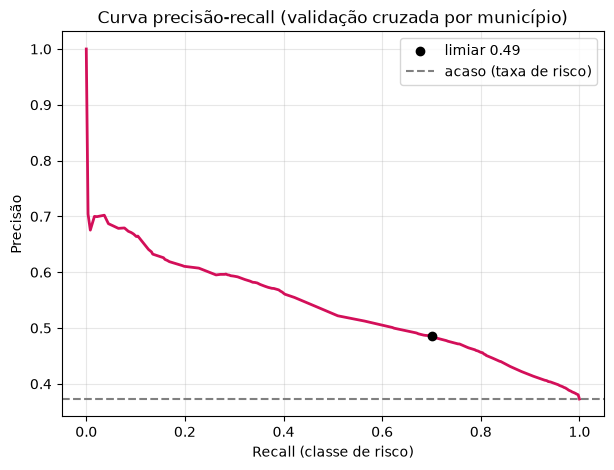

In [5]:
proba_oof = probas_fora_da_amostra(criar_pipeline_arvore(dados.decisoes, **params_arvore),
                                   X_am, y_am, g_am, n_splits=5)
escolha = escolher_limiar(y_am, proba_oof, META_RECALL)
LIMIAR = escolha["limiar"]
print(f"Limiar escolhido: {LIMIAR:.3f} (recall {escolha['recall']:.3f}, precisão {escolha['precisao']:.3f})")
print(f"Valores distintos de probabilidade na validação: {len(np.unique(proba_oof))}")
plot_precisao_recall_cv(escolha, y_am.mean(), "arvore_curva_precisao_recall_cv.png")

## 6. Avaliação final no teste (uma única vez)

Otimização, Aula 4 (`slide18`). A árvore treina com **todo o treino** (sem teto), com os
hiperparâmetros da seção 4 e o limiar da seção 5. `salvar_resultados` grava a tabela, os
parâmetros e as probabilidades do teste, que alimentam a comparação entre modelos.

Treino final: 1,320,423 alunos em 12s | profundidade 5 | folhas 25


,roc_auc,pr_auc,recall,precisao,f1,alertas (% dos alunos)
limiar 0.50,0.664,0.528,0.605,0.517,0.557,0.461
limiar 0.49 (escolhido),0.664,0.528,0.605,0.517,0.557,0.461


Taxa de risco no teste (precisão do acaso): 39.3%
Em risco: 114,219 | encontradas: 69,113 (60.5%) | não encontradas: 45,106
Alertas: 133,783 | corretos: 51.7% | alarmes falsos: 64,670


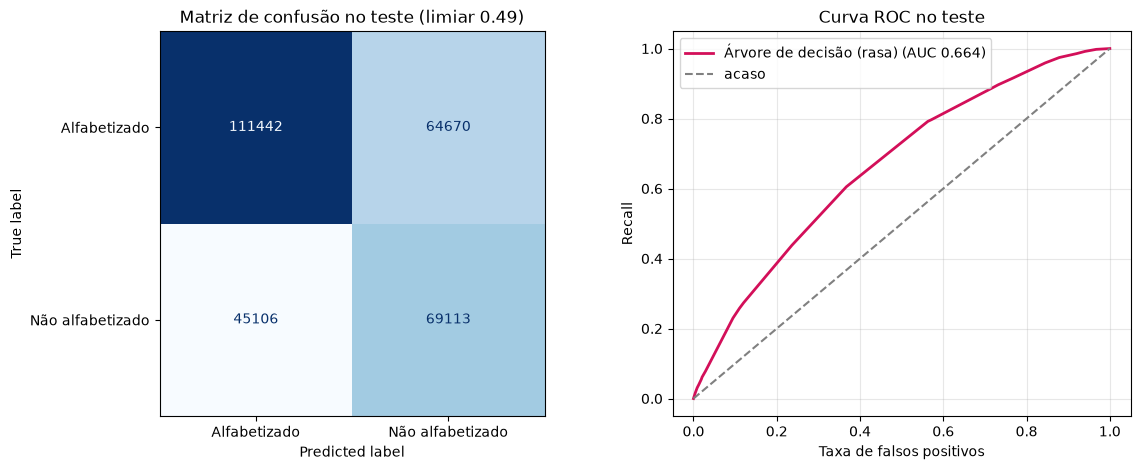

In [6]:
t0 = time.time()
modelo_final = criar_pipeline_arvore(dados.decisoes, **params_arvore).fit(dados.X_treino, dados.y_treino)
arvore = modelo_final.named_steps["modelo"]
print(f"Treino final: {len(dados.y_treino):,} alunos em {time.time() - t0:.0f}s | "
      f"profundidade {arvore.get_depth()} | folhas {arvore.get_n_leaves()}")

proba_teste, tabela_teste = salvar_resultados(NOME, modelo_final, dados, LIMIAR, META_RECALL,
                                              params_arvore, ROTULO)
display(tabela_teste.round(3))

previsto = (proba_teste >= LIMIAR).astype(int)
y_t = dados.y_teste.values
vp = int(((previsto == 1) & (y_t == 1)).sum()); fn = int(((previsto == 0) & (y_t == 1)).sum())
fp = int(((previsto == 1) & (y_t == 0)).sum())
print(f"Taxa de risco no teste (precisão do acaso): {y_t.mean():.1%}")
print(f"Em risco: {vp + fn:,} | encontradas: {vp:,} ({vp / (vp + fn):.1%}) | não encontradas: {fn:,}")
print(f"Alertas: {vp + fp:,} | corretos: {vp / (vp + fp):.1%} | alarmes falsos: {fp:,}")
plot_avaliacao_teste(dados.y_teste, proba_teste, LIMIAR, ROTULO, "arvore_avaliacao_teste.png")

**Leitura** (`TODO`): registrar ROC-AUC, PR-AUC, recall e precisão no teste e compará-los com os
demais modelos (seção 7). Pontos para o README: quanto de desempenho se perde ao trocar um
ensemble por uma árvore de poucas folhas (esperado: pouco) e quantas folhas a árvore tem (cada
folha é um perfil de município que dá para descrever em uma frase).

## 7. Comparação com os outros modelos no mesmo teste

Cada modelo usa o seu próprio limiar (escolhido para o mesmo recall-alvo). Compare principalmente
**ROC-AUC e PR-AUC**, que não dependem do limiar. Os modelos entram na tabela se os notebooks 04
e 05 já foram executados (eles gravam as probabilidades do teste); a regressão logística é
treinada aqui caso ainda não esteja gravada.

In [7]:
if not (PASTA_RELATORIOS / "probas_teste_regressao_logistica.parquet").exists():
    treinar_sem_busca("regressao_logistica", dados, META_RECALL, TETO_ALUNOS)

tabela_comparacao = comparar_teste(dados)
display(tabela_comparacao.round(3))
for rotulo in ["Random Forest", "HistGradientBoosting"]:
    if rotulo not in tabela_comparacao.index:
        print(f"Obs.: {rotulo} ainda não aparece; rode o notebook correspondente e execute esta célula de novo.")

,roc_auc,pr_auc,recall,precisao,f1,alertas (% dos alunos),limiar
HistGradientBoosting,0.674,0.552,0.665,0.509,0.577,0.514,0.474
Random Forest,0.673,0.549,0.694,0.505,0.585,0.540,0.471
Regressão logística,0.672,0.550,0.687,0.505,0.582,0.535,0.466
Árvore de decisão (rasa),0.664,0.528,0.605,0.517,0.557,0.461,0.486


**Leitura** (`TODO`): se os quatro modelos empatam dentro do desvio (~0,01 de AUC), a conclusão
para o README é que **a escolha do algoritmo importa pouco** aqui. Para a recomendação a
gestores, vale preferir o modelo mais simples e explicável (árvore ou regressão logística) e usar
os ensembles como verificação de que não há ganho escondido em interações não lineares.

## 8. A árvore como regras: perfis de município

Cada **folha** é um perfil de município: um conjunto de condições e a taxa de risco **real** dos
alunos que caem nele. A tabela traz, para treino e teste, o número de alunos, de municípios e a
taxa de risco. Se a taxa do teste acompanha a do treino, o perfil **generaliza** para
municípios inéditos.

Como ler: as condições são lidas com "E"; variáveis de UF/região aparecem como `= sim/não`; os
números estão em unidades originais.

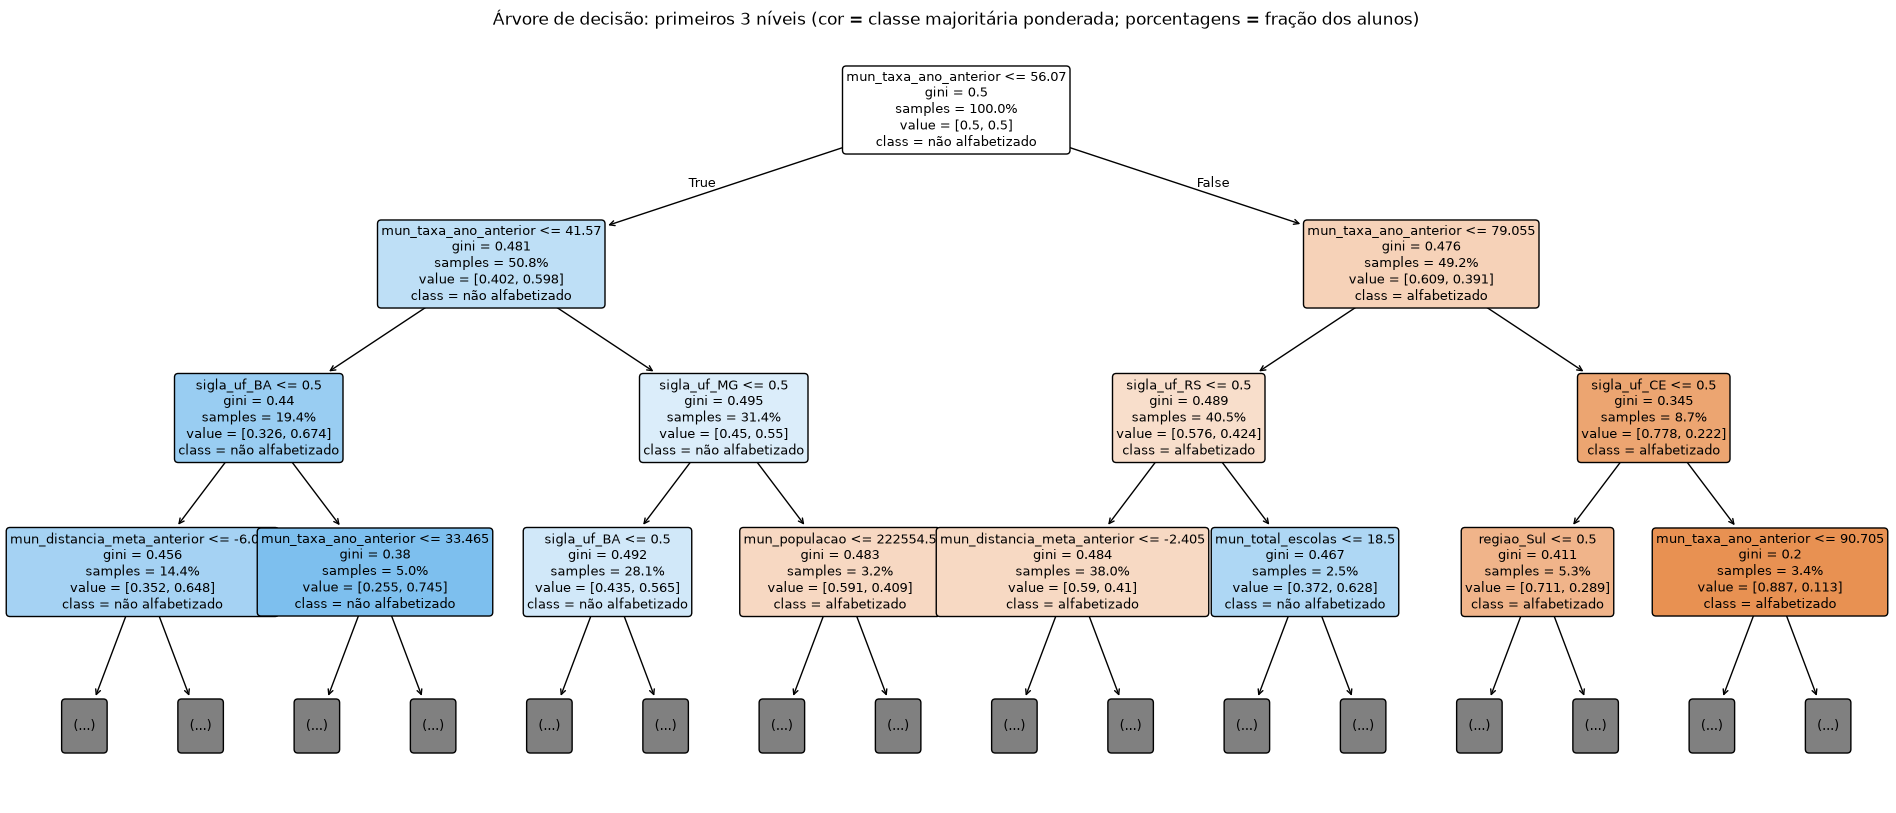

25 perfis (folhas). Taxa de risco média no teste: 39.3%

Perfis de MAIOR risco (pelo treino):


,regra,alunos_treino,municipios_treino,risco_treino,alunos_teste,municipios_teste,risco_teste
0,mun_taxa_ano_anterior <= 56.07 E mun_taxa_ano_anterior <= 41.57 E sigla_uf_BA = sim E mun_taxa_ano_anterior <= 33.47 E mun_pct_indigena > 1.20,14432,48,0.717,2465,9,0.715
1,mun_taxa_ano_anterior <= 56.07 E mun_taxa_ano_anterior <= 41.57 E sigla_uf_BA = sim E mun_taxa_ano_anterior <= 33.47 E mun_pct_indigena <= 1.20,19935,98,0.683,2600,15,0.673
2,mun_taxa_ano_anterior <= 56.07 E mun_taxa_ano_anterior <= 41.57 E sigla_uf_BA = não E mun_distancia_meta_anterior > -6.10,14590,56,0.667,1894,10,0.602
3,mun_taxa_ano_anterior <= 56.07 E mun_taxa_ano_anterior <= 41.57 E sigla_uf_BA = sim E mun_taxa_ano_anterior > 33.47 E mun_pct_va_administracao_publica > 16.56,14072,70,0.647,2644,16,0.619
4,mun_taxa_ano_anterior <= 56.07 E mun_taxa_ano_anterior <= 41.57 E sigla_uf_BA = sim E mun_taxa_ano_anterior > 33.47 E mun_pct_va_administracao_publica <= 16.56,17985,9,0.631,1037,3,0.687


Perfis de MENOR risco (pelo treino):


,regra,alunos_treino,municipios_treino,risco_treino,alunos_teste,municipios_teste,risco_teste
20,mun_taxa_ano_anterior > 56.07 E mun_taxa_ano_anterior > 79.06 E sigla_uf_CE = não E regiao_Sul = sim E mun_indice_envelhecimento <= 69.69,19322,90,0.222,7786,19,0.228
21,mun_taxa_ano_anterior > 56.07 E mun_taxa_ano_anterior > 79.06 E sigla_uf_CE = não E regiao_Sul = não E mun_distancia_meta_anterior <= 6.43,21218,200,0.219,8606,45,0.148
22,mun_taxa_ano_anterior > 56.07 E mun_taxa_ano_anterior > 79.06 E sigla_uf_CE = não E regiao_Sul = não E mun_distancia_meta_anterior > 6.43,15028,188,0.163,4172,49,0.170
23,mun_taxa_ano_anterior > 56.07 E mun_taxa_ano_anterior > 79.06 E sigla_uf_CE = sim E mun_taxa_ano_anterior <= 90.71,20113,39,0.138,5471,15,0.123
24,mun_taxa_ano_anterior > 56.07 E mun_taxa_ano_anterior > 79.06 E sigla_uf_CE = sim E mun_taxa_ano_anterior > 90.71,25395,85,0.035,6002,17,0.044


Perfis com 10 ou mais municípios no teste: 21 de 25 | correlação risco treino x teste: 0.988


In [8]:
plot_arvore(modelo_final, "arvore_regras.png", profundidade_max=3)

regras = regras_da_arvore(modelo_final, {
    "treino": (dados.X_treino, dados.y_treino, dados.g_treino),
    "teste": (dados.X_teste, dados.y_teste, dados.g_teste),
})
regras.to_csv(PASTA_RELATORIOS / "arvore_rasa_regras.csv", index=False, encoding="utf-8-sig")

colunas_regras = ["regra", "alunos_treino", "municipios_treino", "risco_treino",
                  "alunos_teste", "municipios_teste", "risco_teste"]
print(f"{len(regras)} perfis (folhas). Taxa de risco média no teste: {dados.y_teste.mean():.1%}")
print("\nPerfis de MAIOR risco (pelo treino):")
display(regras[colunas_regras].head(5).round(3))
print("Perfis de MENOR risco (pelo treino):")
display(regras[colunas_regras].tail(5).round(3))

estaveis = regras[regras["municipios_teste"] >= 10]
correlacao = estaveis[["risco_treino", "risco_teste"]].corr().iloc[0, 1]
print(f"Perfis com 10 ou mais municípios no teste: {len(estaveis)} de {len(regras)} | "
      f"correlação risco treino x teste: {correlacao:.3f}")

**Como usar e o que cuidar** (`TODO`: escolher 2 ou 3 perfis para destacar no README e no vídeo):

- Prefira perfis com **muitos municípios** no teste: uma folha dominada por poucos municípios
  grandes diz mais sobre esses municípios do que sobre um padrão.
- Os perfis descrevem **onde o risco se concentra**, e por serem baseados em variáveis
  municipais, descrevem municípios, **não alunos**. Não use as regras para rotular crianças.
- É **associação, não causa**. Se `mun_pct_rural` ou `mun_pct_transporte` aparecerem nas regras,
  lembrar que têm valores acima de 100% em 20 a 23% dos municípios (a leitura espera a correção
  na Gold). Condições sobre o **RS** carregam a anomalia de origem documentada na Fase 2.
- Se as primeiras divisões usarem só `mun_taxa_ano_anterior` e `mun_distancia_meta_anterior`, a
  árvore está descrevendo a **inércia** (o município que já ia mal continua mal). A análise sem
  essas duas features está no notebook 04 (seção 12).

## 9. Importância das features e SHAP

A importância interna da árvore (por redução de impureza) e a **permutation importance** no
teste, com amostra de `TETO_PERMUTACAO` alunos por município. Árvores rasas usam poucas
features: a maioria terá importância zero, o que é esperado e informativo.

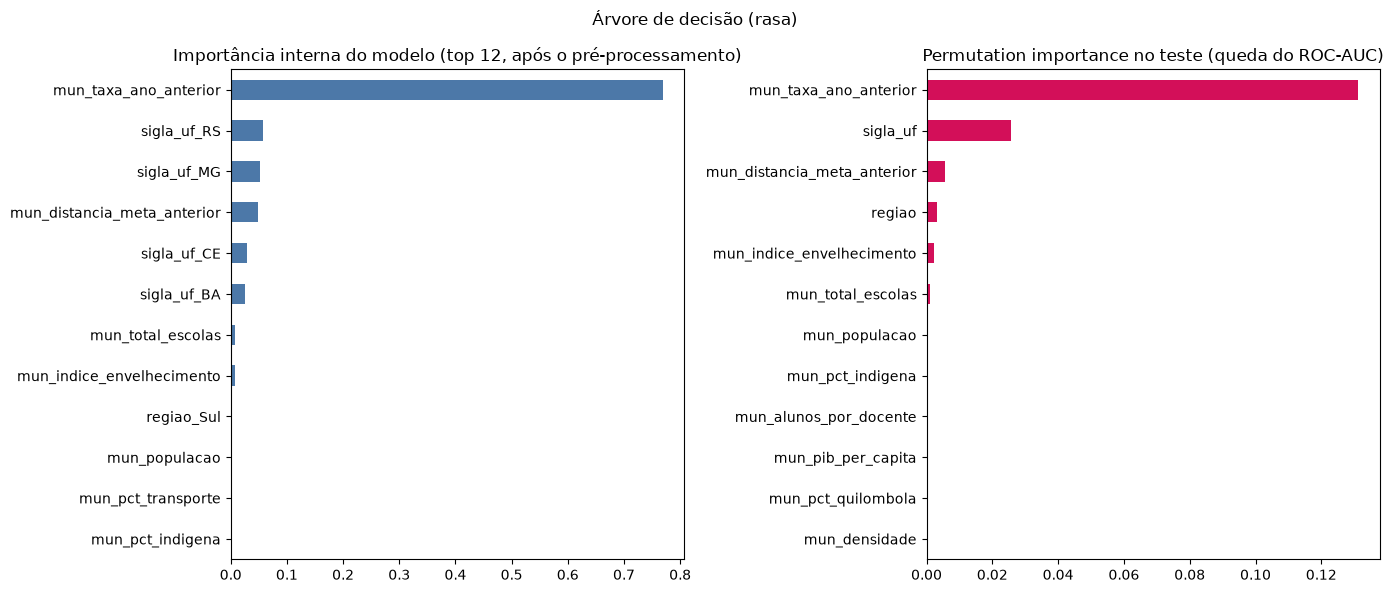

Permutation calculada em 21,575 alunos de 1,090 municípios
Features com importância de impureza maior que zero: 13 de 52


,queda do ROC-AUC (permutation)
mun_taxa_ano_anterior,0.1313
sigla_uf,0.0257
mun_distancia_meta_anterior,0.0057
regiao,0.0031
mun_indice_envelhecimento,0.0022
mun_total_escolas,0.0012
mun_populacao,0.0003
mun_pct_indigena,0.0000
mun_alunos_por_docente,0.0000
mun_pib_per_capita,0.0000


In [9]:
cols = list(dados.X_treino.columns)
X_perm, y_perm, g_perm = limitar_por_municipio(dados.X_teste, dados.y_teste, dados.g_teste, TETO_PERMUTACAO)
imp_perm = importancia_permutacao(modelo_final, X_perm[cols], y_perm, n_repeats=5)

pre = modelo_final.named_steps["pre"]
nomes_saida = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
imp_impureza = pd.Series(arvore.feature_importances_, index=nomes_saida).sort_values(ascending=False)

plot_importancias(imp_perm, imp_impureza, ROTULO, "arvore_importancia_features.png")
print(f"Permutation calculada em {len(y_perm):,} alunos de {g_perm.nunique():,} municípios")
print(f"Features com importância de impureza maior que zero: {(imp_impureza > 0).sum()} de {len(imp_impureza)}")
display(imp_perm.head(10).round(4).to_frame("queda do ROC-AUC (permutation)"))

shape dos valores SHAP (classe de risco): (3270, 52)


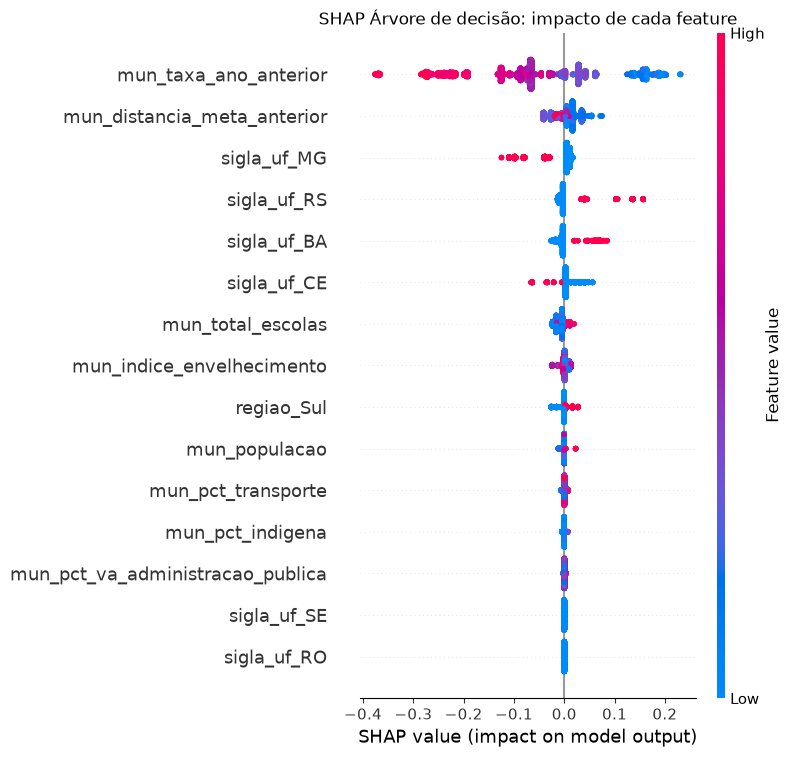

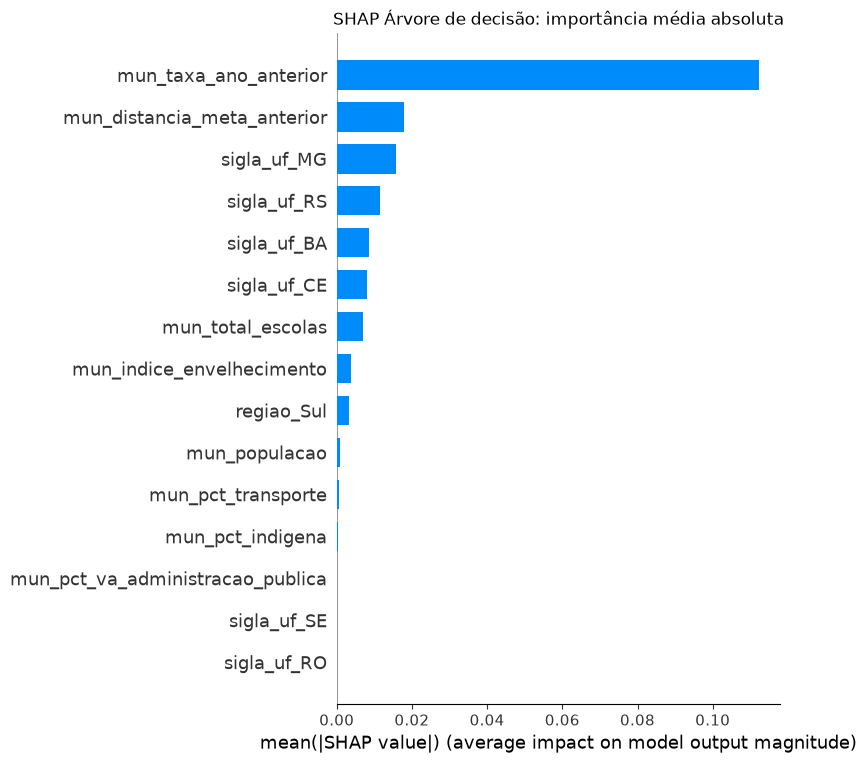

,|SHAP| médio
mun_taxa_ano_anterior,0.1123
mun_distancia_meta_anterior,0.0178
sigla_uf_MG,0.0158
sigla_uf_RS,0.0116
sigla_uf_BA,0.0087
sigla_uf_CE,0.0081
mun_total_escolas,0.0070
mun_indice_envelhecimento,0.0038
regiao_Sul,0.0032
mun_populacao,0.0009


In [10]:
X_shap_bruto, _, _ = limitar_por_municipio(dados.X_teste, dados.y_teste, dados.g_teste, TETO_SHAP)
valores, X_shap, nomes_shap = calcular_shap(modelo_final, X_shap_bruto[cols])
print("shape dos valores SHAP (classe de risco):", valores.shape)
plot_shap(valores, X_shap, nomes_shap, "arvore_shap", titulo="Árvore de decisão")

shap_medio = pd.Series(np.abs(valores).mean(axis=0), index=nomes_shap).sort_values(ascending=False)
display(shap_medio.head(10).round(4).to_frame("|SHAP| médio"))

**Leitura** (`TODO`): comparar o top 5 de SHAP e de permutation com o da Random Forest e do
boosting. Se o ranking é parecido (esperado: `mun_taxa_ano_anterior`, `mun_distancia_meta_anterior`
e UF/região no topo), a conclusão sobre os fatores é robusta ao algoritmo. Lembrar que a
permutation agrupa as colunas de UF numa só (a feature original `sigla_uf`), enquanto o SHAP
mostra cada UF separada, por isso a UF parece menor no SHAP.

## Síntese

In [11]:
linha = tabela_teste.iloc[1]
print(f"Modelo: {ROTULO} {params_arvore} | profundidade {arvore.get_depth()} | folhas {arvore.get_n_leaves()}")
print(f"Busca: melhor AUC {melhor_linha['roc_auc']:.3f}; {len(empatadas)} de {len(tabela_busca)} combinações empatadas (1 desvio padrão)")
print(f"Teste (limiar {LIMIAR:.2f}): ROC-AUC {linha['roc_auc']:.3f} | PR-AUC {linha['pr_auc']:.3f} | "
      f"recall {linha['recall']:.3f} | precisão {linha['precisao']:.3f}")
print(f"Perfis estáveis no teste (10 ou mais municípios): {len(estaveis)} de {len(regras)} | correlação de risco treino x teste: {correlacao:.3f}")
print("Top 5 permutation:", ", ".join(imp_perm.head(5).index))
print("Top 5 SHAP:", ", ".join(shap_medio.head(5).index))

Modelo: Árvore de decisão (rasa) {'max_depth': 5, 'min_samples_leaf': 0.01} | profundidade 5 | folhas 25
Busca: melhor AUC 0.675; 7 de 24 combinações empatadas (1 desvio padrão)
Teste (limiar 0.49): ROC-AUC 0.664 | PR-AUC 0.528 | recall 0.605 | precisão 0.517
Perfis estáveis no teste (10 ou mais municípios): 21 de 25 | correlação de risco treino x teste: 0.988
Top 5 permutation: mun_taxa_ano_anterior, sigla_uf, mun_distancia_meta_anterior, regiao, mun_indice_envelhecimento
Top 5 SHAP: mun_taxa_ano_anterior, mun_distancia_meta_anterior, sigla_uf_MG, sigla_uf_RS, sigla_uf_BA


**Próximos passos:** completar a tabela comparativa dos quatro modelos (`python -m
src.evaluation.comparar_teste`); escolher os perfis de risco que entram no README e no vídeo
executivo; decidir o recall-alvo com a capacidade de atendimento da rede; e atacar a pergunta de
negócio que ainda não tem modelo: **"quais regiões possuem padrões semelhantes?"**
(clusterização).